<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 5</b><br>Метод ліктя. Кластеризація даних<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Завдання 1. Завантажити Iris та показати перші 5 рядків.
from sklearn.datasets import load_iris
iris=load_iris(as_frame=True)
display(iris.frame.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


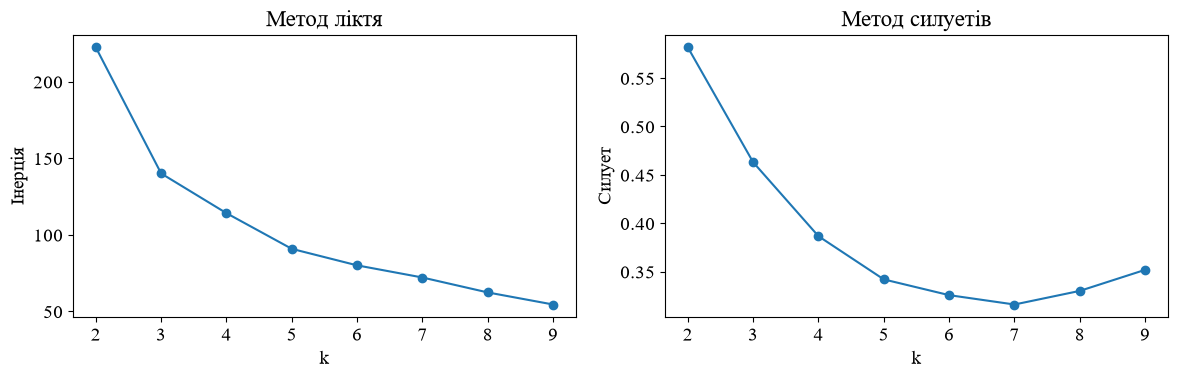

Лікоть за відстанню від хорди: 4 ; максимальний силует: 2


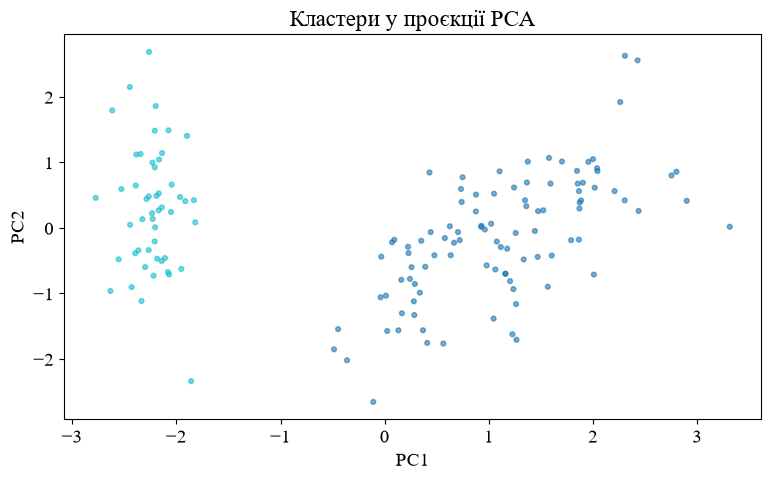

Висновок: обрано k = 2 за максимальним силуетом 0.582 . Лікоть пропонує 4 . Проєкція PCA спрощує багатовимірну структуру.


In [3]:
# Завдання 1. Методи ліктя та силуетів, вибір кількості кластерів і візуалізація.
cluster_X=iris.data
cluster_X=StandardScaler().fit_transform(SimpleImputer().fit_transform(cluster_X))
ks=list(range(2,10));inertia=[];sil=[]
for k in ks:
    km=KMeans(n_clusters=k,n_init=10,random_state=25)
    labels=km.fit_predict(cluster_X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(cluster_X,labels,sample_size=min(len(cluster_X),2000),random_state=25))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(ks,inertia,'o-');axes[0].set(xlabel='k',ylabel='Інерція',title='Метод ліктя')
axes[1].plot(ks,sil,'o-');axes[1].set(xlabel='k',ylabel='Силует',title='Метод силуетів');plt.tight_layout();plt.show()
points=np.column_stack([ks,inertia]).astype(float)
points=(points-points.min(axis=0))/(points.max(axis=0)-points.min(axis=0))
line=points[-1]-points[0]
distance=np.abs(line[0]*(points[:,1]-points[0,1])-line[1]*(points[:,0]-points[0,0]))/np.linalg.norm(line)
elbow_k=ks[int(distance.argmax())]
best_k=ks[int(np.argmax(sil))]
print('Лікоть за відстанню від хорди:',elbow_k,'; максимальний силует:',best_k)
km=KMeans(n_clusters=best_k,n_init=10,random_state=25)
labels=km.fit_predict(cluster_X)
xy=PCA(n_components=2).fit_transform(cluster_X)
plt.scatter(xy[:,0],xy[:,1],c=labels,cmap='tab10',s=12,alpha=0.6)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('Кластери у проєкції PCA');plt.show()
print('Висновок: обрано k =',best_k,'за максимальним силуетом',round(max(sil),3),'. Лікоть пропонує',elbow_k,'. Проєкція PCA спрощує багатовимірну структуру.')

In [4]:
# Висновок. Завдання 1. Кластери знайдені без використання назв видів. Кількість кластерів за геометричним критерієм може відрізнятися від трьох біологічних видів Iris.

In [5]:
# Завдання 2. Завантажити датасет, попередній аналіз, тип задачі. Використано наданий Student_data.csv для прогнозу GPA.
df=pd.read_csv(data_path('Student_data.csv'))

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

print('Задача регресії: GPA є числовою оцінкою. GradeClass залежить від оцінки, тому не використовую його як предиктор; StudentID — ідентифікатор.')

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Розмір: (2392, 15)


StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Дублікати: 0


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


Задача регресії: GPA є числовою оцінкою. GradeClass залежить від оцінки, тому не використовую його як предиктор; StudentID — ідентифікатор.


In [6]:
# Завдання 2. Три моделі оцінки GPA. Поділ 80/20 та налаштування моделей крос-валідацією. Масштабування всередині Pipeline.
X=df.drop(columns=['GPA','GradeClass','StudentID']);y=df.GPA
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)
cv=KFold(n_splits=3,shuffle=True,random_state=25)

models={'Лінійна':LinearRegression(),'Ridge':Ridge(),'Ліс':RandomForestRegressor(random_state=25,n_jobs=1)}
grids={'Лінійна':{'model__fit_intercept':[True,False]},'Ridge':{'model__alpha':[0.1,1,10,100]},'Ліс':{'model__n_estimators':[80],'model__max_depth':[6,None]}}
fitted={}
rows=[]
for name,model in models.items():
    pipe=Pipeline([('imputer',SimpleImputer()),('scale',StandardScaler()),('model',model)])
    grid=GridSearchCV(pipe,grids[name],cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
    grid.fit(X_train,y_train)
    fitted[name]=grid
    pred=grid.predict(X_test)
    rows.append([name,-grid.best_score_,mean_squared_error(y_test,pred),r2_score(y_test,pred),grid.best_params_])
results=pd.DataFrame(rows,columns=['Модель','CV MSE','Test MSE','Test R2','Параметри'])
display(results)
best_name=results.loc[results['CV MSE'].idxmin(),'Модель']
print('Найкраща за CV:',best_name)

,Модель,CV MSE,Test MSE,Test R2,Параметри
0,Лінійна,0.038904,0.038939,0.956321,{'model__fit_intercept': True}
1,Ridge,0.038904,0.038939,0.956321,{'model__alpha': 0.1}
2,Ліс,0.062166,0.058644,0.934217,"{'model__max_depth': None, 'model__n_estimator..."


Найкраща за CV: Лінійна


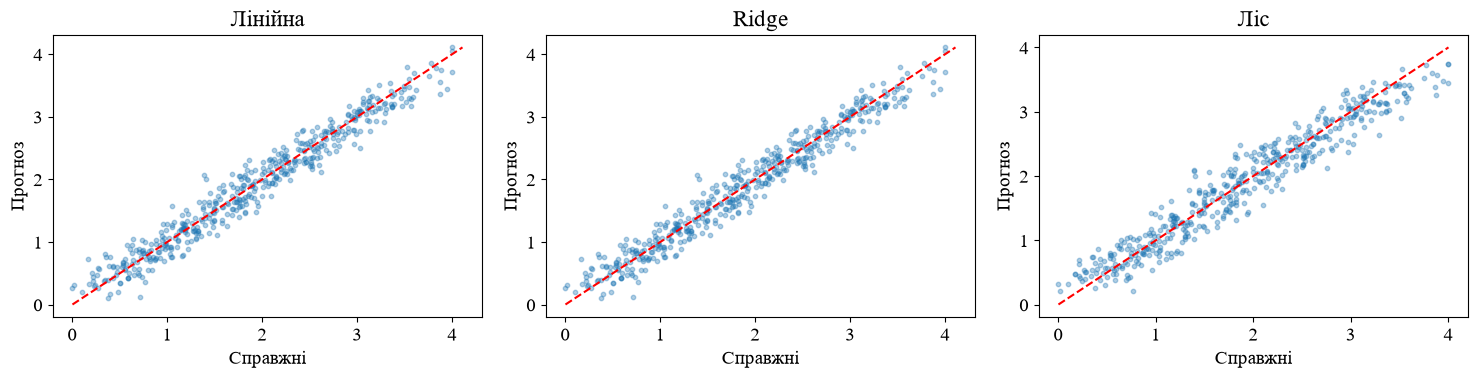

,Справжні,Лінійна,Ridge,Ліс
790,0.604613,0.881022,0.881077,0.932939
987,2.096033,1.941532,1.941530,2.039796
1865,1.261588,1.301600,1.301629,1.266277
1682,3.121119,3.258475,3.258399,3.170429
737,0.568468,0.650617,0.650685,0.536755
1653,1.794667,1.904721,1.904724,1.998792
349,2.833760,2.774777,2.774732,2.745798
2192,0.818126,0.723499,0.723558,0.720979
2299,1.027728,0.923158,0.923208,0.995541
1,3.042915,3.097687,3.097627,2.965752


Висновок за результатами: найкраща CV-модель — Лінійна


,Test MSE,Test R2
0,0.038939,0.956321


In [7]:
# Завдання 2. Три моделі оцінки GPA. Графіки та справжні й прогнозовані значення всіх моделей.
fig,axes=plt.subplots(1,len(fitted),figsize=(5*len(fitted),4),squeeze=False)
for ax,(name,model) in zip(axes.flat,fitted.items()):
    pred=model.predict(X_test)
    ax.scatter(y_test,pred,alpha=0.35,s=10)
    lo,hi=min(y_test.min(),pred.min()),max(y_test.max(),pred.max())
    ax.plot([lo,hi],[lo,hi],'r--');ax.set_title(name);ax.set_xlabel('Справжні');ax.set_ylabel('Прогноз')
plt.tight_layout();plt.show()
comparison=pd.DataFrame({'Справжні':y_test})
for name,model in fitted.items():comparison[name]=model.predict(X_test)
display(comparison.head(20))
print('Висновок за результатами: найкраща CV-модель —',best_name)
display(results.loc[results['Модель']==best_name,['Test MSE','Test R2']])

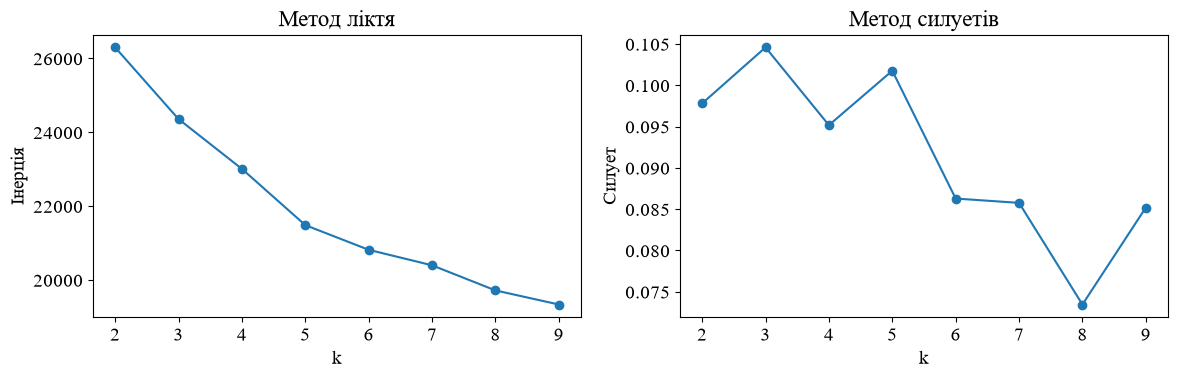

Лікоть за відстанню від хорди: 5 ; максимальний силует: 3


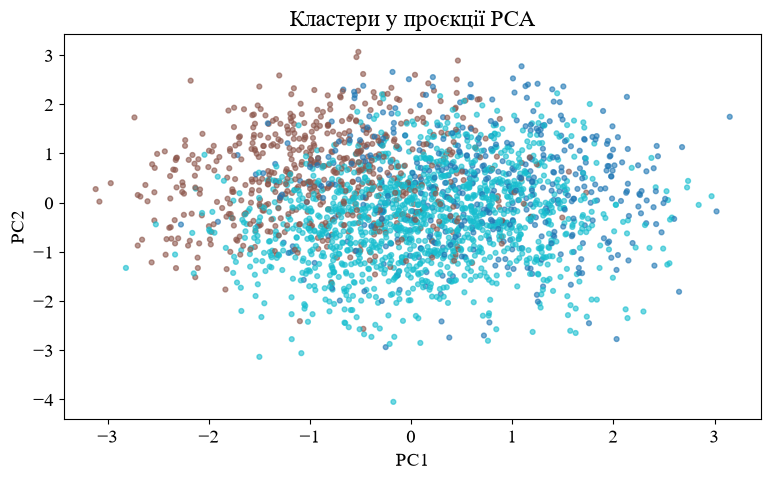

Висновок: обрано k = 3 за максимальним силуетом 0.105 . Лікоть пропонує 5 . Проєкція PCA спрощує багатовимірну структуру.


In [8]:
# Завдання 2. Кластеризація. Методи ліктя та силуетів, вибір кількості кластерів і візуалізація.
cluster_X=df.drop(columns=['GPA','GradeClass','StudentID'])
cluster_X=StandardScaler().fit_transform(SimpleImputer().fit_transform(cluster_X))
ks=list(range(2,10));inertia=[];sil=[]
for k in ks:
    km=KMeans(n_clusters=k,n_init=10,random_state=25)
    labels=km.fit_predict(cluster_X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(cluster_X,labels,sample_size=min(len(cluster_X),2000),random_state=25))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(ks,inertia,'o-');axes[0].set(xlabel='k',ylabel='Інерція',title='Метод ліктя')
axes[1].plot(ks,sil,'o-');axes[1].set(xlabel='k',ylabel='Силует',title='Метод силуетів');plt.tight_layout();plt.show()
points=np.column_stack([ks,inertia]).astype(float)
points=(points-points.min(axis=0))/(points.max(axis=0)-points.min(axis=0))
line=points[-1]-points[0]
distance=np.abs(line[0]*(points[:,1]-points[0,1])-line[1]*(points[:,0]-points[0,0]))/np.linalg.norm(line)
elbow_k=ks[int(distance.argmax())]
best_k=ks[int(np.argmax(sil))]
print('Лікоть за відстанню від хорди:',elbow_k,'; максимальний силует:',best_k)
km=KMeans(n_clusters=best_k,n_init=10,random_state=25)
labels=km.fit_predict(cluster_X)
xy=PCA(n_components=2).fit_transform(cluster_X)
plt.scatter(xy[:,0],xy[:,1],c=labels,cmap='tab10',s=12,alpha=0.6)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('Кластери у проєкції PCA');plt.show()
print('Висновок: обрано k =',best_k,'за максимальним силуетом',round(max(sil),3),'. Лікоть пропонує',elbow_k,'. Проєкція PCA спрощує багатовимірну структуру.')

In [9]:
# Висновок. Завдання 2. GPA прогнозується як неперервна величина. Виключено залежну від оцінки GradeClass, щоб не було витоку відповіді. Порівняно три моделі і виконано незалежну кластеризацію ознак; її результат не є оцінкою успішності.